# MTA Subway Hourly Ridership – *Exploratory Data Analysis*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fxrdhan/mta-subway-bigdata/blob/main/notebooks/MTA_Subway_Hourly_Ridership_EDA_2025-01_2026-10.ipynb)

> **Data: *cutoff* 2026-10-08 23:00.** Notebook ini membaca dataset bersih hasil `notebooks/MTA_Subway_Hourly_Ridership_2025-01_2026-10.ipynb` (bagian III dan IV) dan tidak mengunduh ulang data dari API, sehingga angkanya tetap sama setiap kali dijalankan.

### V. *Exploratory Data Analysis* (EDA)

EDA ini mencari pola volume penumpang yang menjadi dasar tahap berikutnya: pola jam dan hari untuk klasifikasi *peak/off-peak*, tren waktu untuk peramalan, porsi OMNY dan MetroCard, sebaran stasiun, profil jam per stasiun untuk *clustering*, serta bentuk distribusi target regresi. Seluruh agregasi dijalankan dengan DuckDB langsung pada file Parquet, dan hanya hasil agregatnya yang dimuat ke `pandas`.

#### 1. Persiapan

Impor pustaka. `matplotlib` dan `numpy` dipakai untuk grafik; sisanya sama dengan notebook *data wrangling*.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | duckdb {duckdb.__version__}")

Python 3.13.16 | pandas 2.2.3 | duckdb 1.3.2


Parameter: nama file bersih dan nilai acuannya. File dicari di Google Drive (tempat notebook *data wrangling* menyalinnya bila `SAVE_TO_DRIVE` dicentang), lalu di folder kerja `/content`. `EXPECTED` memastikan file yang terbaca adalah versi *cutoff* 2026-10-08, bukan versi lain dengan nama serupa.

In [2]:
CLEAN_NAME = "mta_subway_hourly_ridership_clean_2025-01_2026-10.parquet"
CANDIDATES = [Path("/content/drive/MyDrive") / CLEAN_NAME, Path("/content/mta_subway/04_clean") / CLEAN_NAME]
EXPECTED = {"rows": 46_363_790, "ridership": 2_325_387_032, "transfers": 116_471_753}
IN_COLAB = "google.colab" in sys.modules

AM_HOURS, PM_HOURS = range(6, 10), range(16, 20)  # 06:00-09:59 and 16:00-19:59

Fungsi bantu tampilan (sama dengan notebook *data wrangling*) dan gaya grafik. Warna kategori dipakai dalam urutan tetap (biru, oranye, aqua), heatmap memakai satu gradasi biru, dan garis bantu dibuat tipis agar data lebih menonjol.

In [3]:
def fmt(x, n=0):
    """Format numbers Indonesian-style: 45243727 -> 45.243.727; 10.63 (n=1) -> 10,6."""
    return f"{x:,.{n}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def show_table(df, n=0):
    """Render a DataFrame without index, with dot thousands separators and no line wrapping."""
    return (
        df.style.format(thousands=".", decimal=",", precision=n)
        .hide(axis="index")
        .set_table_styles([{"selector": "th, td", "props": [("white-space", "nowrap")]}])
    )


BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
MILLIONS = FuncFormatter(lambda v, _: fmt(v / 1e6, 1))
THOUSANDS = FuncFormatter(lambda v, _: fmt(v / 1e3))
PERCENT = FuncFormatter(lambda v, _: f"{fmt(v)}%")

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "lines.linewidth": 2, "legend.frameon": False,
})

File bersih dibuka sebagai *view* DuckDB `mta`. Di Colab, Google Drive di-*mount* lebih dulu. Sel berhenti dengan galat bila file tidak ditemukan atau isinya berbeda dengan nilai acuan.

In [4]:
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")

CLEAN_PATH = next((p for p in CANDIDATES if p.exists()), None)
if CLEAN_PATH is None:
    raise FileNotFoundError(f"{CLEAN_NAME} not found in {[str(p.parent) for p in CANDIDATES]}; run the data wrangling notebook first")

con = duckdb.connect()
con.execute("SET enable_progress_bar=false")
con.execute(f"CREATE OR REPLACE VIEW mta AS SELECT * FROM read_parquet('{CLEAN_PATH}')")

rows, riders, transfers = con.sql("SELECT count(*), sum(ridership), sum(transfers) FROM mta").fetchone()
assert (rows, riders, transfers) == (EXPECTED["rows"], EXPECTED["ridership"], EXPECTED["transfers"]), "Clean file differs from the reference values."
print(f"File : {CLEAN_PATH}")
print(f"Rows : {fmt(rows)} | ridership {fmt(riders)} | transfers {fmt(transfers)} (match the reference)")

File : /content/mta_subway/04_clean/mta_subway_hourly_ridership_clean_2025-01_2026-10.parquet
Rows : 46.363.790 | ridership 2.325.387.032 | transfers 116.471.753 (match the reference)


Tiga tabel agregat menjadi bahan sebagian besar analisis: total penumpang per jam untuk seluruh sistem (`hourly`), per hari (`daily`), dan per stasiun (`stations`). Jam peralihan DST (`is_dst_transition`) dikeluarkan dari tabel per jam karena labelnya ambigu (satu label bisa berisi dua jam), tetapi tetap dihitung pada total harian karena penumpangnya nyata.

In [5]:
hourly = con.sql("""
    SELECT transit_timestamp AS ts, sum(ridership) AS riders
    FROM mta WHERE NOT is_dst_transition GROUP BY 1 ORDER BY 1""").df()
hourly["hour"] = hourly["ts"].dt.hour
hourly["weekday"] = hourly["ts"].dt.dayofweek  # 0 = Monday
hourly["day_type"] = np.where(hourly["weekday"] < 5, "Weekday", "Weekend")

daily = con.sql("""
    SELECT CAST(transit_timestamp AS DATE) AS day, sum(ridership) AS riders, sum(transfers) AS transfers
    FROM mta GROUP BY 1 ORDER BY 1""").df().astype({"riders": "int64", "transfers": "int64"})
daily["day"] = pd.to_datetime(daily["day"])
daily["weekday"] = daily["day"].dt.dayofweek
N_DAYS = len(daily)

stations = con.sql("""
    SELECT station_complex_id, any_value(station_complex) AS station_complex, any_value(borough) AS borough,
           any_value(latitude) AS latitude, any_value(longitude) AS longitude, sum(ridership) AS riders
    FROM mta GROUP BY 1 ORDER BY riders DESC""").df().astype({"riders": "int64"})
stations["avg_daily"] = stations["riders"] / N_DAYS

print(f"hourly: {fmt(len(hourly))} hours | daily: {fmt(N_DAYS)} days | stations: {fmt(len(stations))}")

hourly: 15.501 hours | daily: 646 days | stations: 428


#### 2. Gambaran Umum

Ringkasan volume penumpang pada seluruh periode:

In [6]:
omny_share = con.sql("SELECT 100.0 * sum(ridership) FILTER (WHERE payment_method = 'omny') / sum(ridership) FROM mta").fetchone()[0]
weekday_mean = daily.loc[daily["weekday"] < 5, "riders"].mean()
weekend_mean = daily.loc[daily["weekday"] >= 5, "riders"].mean()

show_table(pd.DataFrame([
    ("Period", f"{daily['day'].min():%Y-%m-%d} to {daily['day'].max():%Y-%m-%d} ({fmt(N_DAYS)} days)"),
    ("Station complexes", fmt(len(stations))),
    ("Total ridership", fmt(riders)),
    ("Mean riders per day (all days)", fmt(daily["riders"].mean())),
    ("Mean riders per weekday (Mon-Fri)", fmt(weekday_mean)),
    ("Mean riders per weekend day (Sat-Sun)", fmt(weekend_mean)),
    ("Free transfers / ridership", f"{fmt(100 * transfers / riders, 2)}%"),
    ("OMNY share of ridership", f"{fmt(omny_share, 2)}%"),
], columns=["Metric", "Value"]))

Metric,Value
Period,2025-01-01 to 2026-10-08 (646 days)
Station complexes,428
Total ridership,2.325.387.032
Mean riders per day (all days),3.599.670
Mean riders per weekday (Mon-Fri),4.054.198
Mean riders per weekend day (Sat-Sun),2.458.410
Free transfers / ridership,"5,01%"
OMNY share of ridership,"88,12%"


Total penumpang per hari beserta rata-rata bergerak 7 hari. Rata-rata 7 hari meredam pola mingguan sehingga tren dan penurunan musiman lebih terlihat.

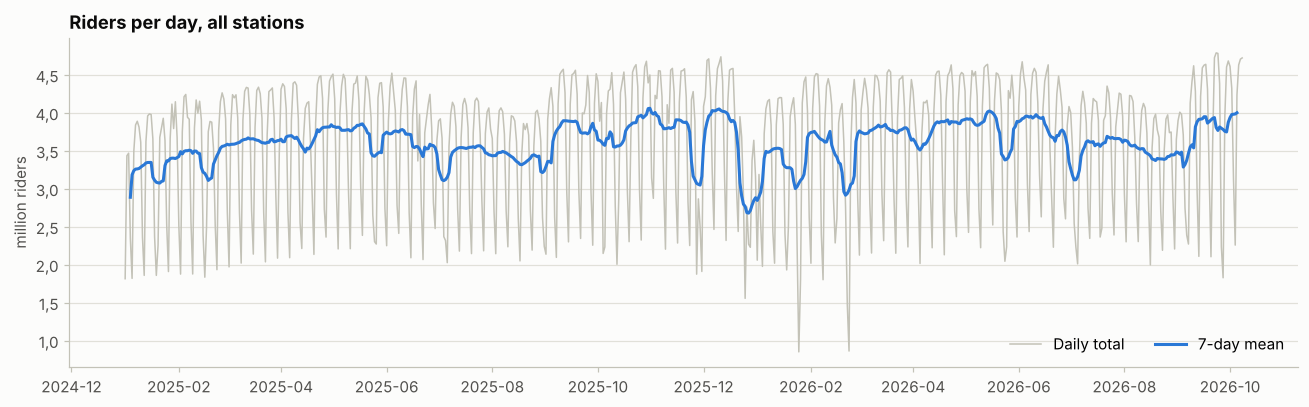

In [7]:
rolling = daily.set_index("day")["riders"].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(daily["day"], daily["riders"], color=AXIS, linewidth=1, label="Daily total")
ax.plot(rolling.index, rolling.values, color=BLUE, label="7-day mean")
ax.set(title="Riders per day, all stations", ylabel="million riders")
ax.yaxis.set_major_formatter(MILLIONS)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc="lower right", ncols=2)
plt.tight_layout()
plt.show()

Hari kerja (Senin sampai Jumat) dengan penumpang paling sedikit, dan hari dengan penumpang paling banyak. Hari kerja yang sangat sepi biasanya hari libur atau gangguan cuaca.

In [8]:
def day_rows(df):
    return df.assign(day=df["day"].dt.strftime("%Y-%m-%d"), weekday=df["day"].dt.day_name())[["day", "weekday", "riders"]]


print("Lowest weekdays")
display(show_table(day_rows(daily[daily["weekday"] < 5].nsmallest(8, "riders"))))
print("Highest days")
display(show_table(day_rows(daily.nlargest(5, "riders"))))

Lowest weekdays


day,weekday,riders
2026-02-23,Monday,861.364
2025-12-25,Thursday,1.554.791
2026-01-26,Monday,1.803.654
2025-01-01,Wednesday,1.813.725
2025-11-27,Thursday,1.873.663
2026-01-01,Thursday,2.057.867
2025-09-01,Monday,2.136.373
2026-05-25,Monday,2.233.053


Highest days


day,weekday,riders
2026-09-23,Wednesday,4.787.759
2026-09-24,Thursday,4.780.534
2025-12-11,Thursday,4.736.294
2026-09-22,Tuesday,4.724.155
2026-10-08,Thursday,4.721.108


**Temuan:**

- Rata-rata 3,60 juta penumpang per hari. Hari kerja rata-rata 4,05 juta, sedangkan akhir pekan 2,46 juta (sekitar 61% hari kerja), sehingga pola mingguan tampak sebagai pita naik turun yang rapat pada grafik harian.
- Enam dari delapan hari kerja tersepi adalah hari libur nasional Amerika Serikat: Natal (25 Desember 2025), Tahun Baru (1 Januari 2025 dan 2026), Thanksgiving (27 November 2025), Labor Day (1 September 2025), dan Memorial Day (25 Mei 2026).
- Dua penurunan paling tajam bukan hari libur: Minggu-Senin 25-26 Januari 2026 (850.416 lalu 1.803.654 penumpang; 25 Januari adalah hari tersepi di seluruh periode) dan Minggu-Senin 22-23 Februari 2026 (1.470.158 lalu 861.364). Keduanya pulih pada hari berikutnya, pola yang mirip dampak cuaca ekstrem, tetapi penyebabnya tidak tercatat di dataset dan perlu dicek ke sumber lain.
- Rata-rata 7 hari turun pada akhir Desember sampai awal Januari dan pada musim panas, lalu naik lagi pada September.
- Implikasi untuk peramalan: model memerlukan fitur hari dalam pekan dan hari libur, dan hari-hari anomali seperti Januari dan Februari 2026 perlu ditandai agar tidak dianggap pola normal.

#### 3. Pola Jam dan Hari

Rata-rata penumpang per jam untuk hari kerja dan akhir pekan. Setiap titik adalah rata-rata total sistem pada jam tersebut di seluruh hari dengan tipe yang sama.

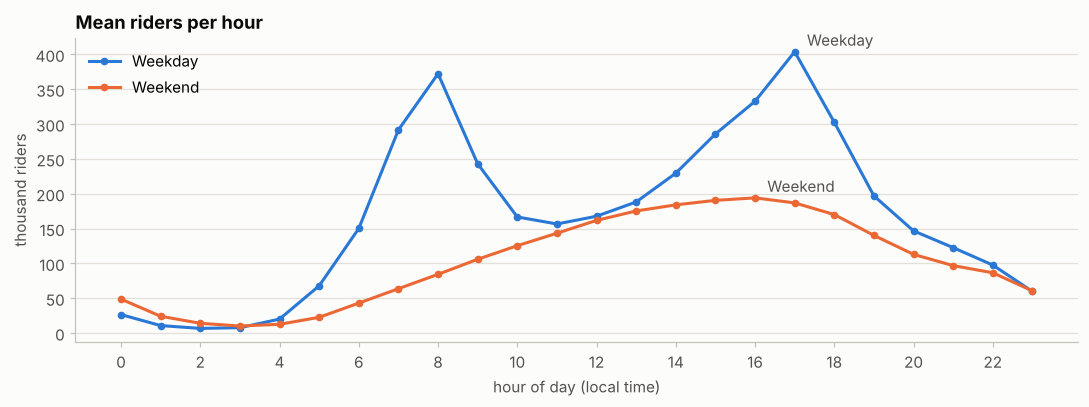

In [9]:
profile = hourly.groupby(["day_type", "hour"])["riders"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(10, 3.8))
for day_type, color in [("Weekday", BLUE), ("Weekend", ORANGE)]:
    ax.plot(profile.index, profile[day_type], color=color, marker="o", markersize=4, label=day_type)
    peak = profile[day_type].idxmax()
    ax.annotate(day_type, (peak, profile.loc[peak, day_type]), xytext=(8, 4), textcoords="offset points", color=INK_2)
ax.set(title="Mean riders per hour", xlabel="hour of day (local time)", ylabel="thousand riders", xticks=range(0, 24, 2))
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Jam tersibuk pada hari kerja dan porsinya terhadap total satu hari:

In [10]:
weekday_profile = profile["Weekday"]
peaks = weekday_profile.nlargest(4).round().astype("int64").rename("mean_riders").reset_index()
peaks["share_of_day_pct"] = 100 * peaks["mean_riders"] / weekday_profile.sum()
peaks["hour"] = peaks["hour"].map(lambda h: f"{h:02d}:00-{h:02d}:59")
show_table(peaks, 1)

hour,mean_riders,share_of_day_pct
17:00-17:59,403.764,"10,0"
08:00-08:59,372.230,"9,2"
16:00-16:59,332.706,"8,2"
18:00-18:59,302.586,"7,5"


Heatmap rata-rata penumpang menurut hari dan jam. Warna lebih gelap berarti lebih banyak penumpang.

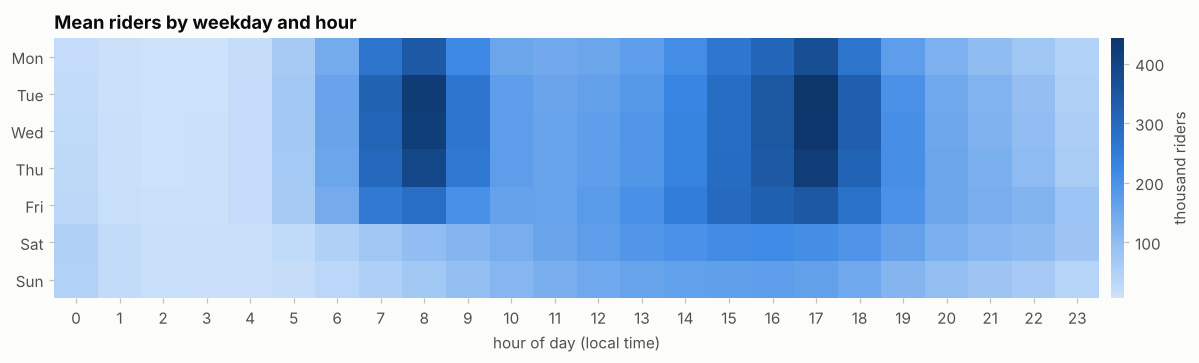

In [11]:
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
grid = hourly.groupby(["weekday", "hour"])["riders"].mean().unstack(1)

fig, ax = plt.subplots(figsize=(12, 3.4))
image = ax.imshow(grid.values, aspect="auto", cmap=SEQ_BLUE)
ax.set(title="Mean riders by weekday and hour", xlabel="hour of day (local time)", xticks=range(24), yticks=range(7), yticklabels=DAY_NAMES)
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
bar = fig.colorbar(image, ax=ax, pad=0.01, format=THOUSANDS)
bar.set_label("thousand riders", color=INK_2)
bar.outline.set_visible(False)
plt.tight_layout()
plt.show()

**Temuan:**

- Hari kerja punya dua puncak: pukul 08.00 (rata-rata 372.230 penumpang, 9,2% dari total hari itu) dan pukul 17.00 (403.764 penumpang, 10,0%). Empat jam tersibuk (17.00, 08.00, 16.00, 18.00) menampung 34,8% penumpang hari kerja.
- Akhir pekan tidak punya puncak pagi; penumpang naik perlahan sampai sekitar pukul 16.00 (±194 ribu per jam), kurang dari separuh puncak sore hari kerja.
- Pada heatmap, Selasa sampai Kamis paling padat pada kedua jam sibuk, sedangkan Senin dan Jumat lebih rendah. Pukul 00.00 akhir pekan justru lebih ramai daripada hari kerja (sekitar 49 ribu dibanding 27 ribu).
- Pukul 01.00-04.00 adalah jam paling sepi (di bawah 25 ribu penumpang per jam pada semua hari).
- Implikasi untuk klasifikasi *peak/off-peak*: batas *peak* sebaiknya bergantung pada tipe hari. Satu ambang yang sama untuk semua hari akan menandai hampir seluruh sore akhir pekan sebagai *off-peak*, padahal pada akhir pekan itulah jam tersibuknya.

#### 4. Tren Bulanan

Rata-rata penumpang per hari untuk setiap bulan. Rata-rata harian dipakai, bukan total bulanan, karena jumlah hari tiap bulan berbeda dan Oktober 2026 baru berisi 8 hari (ditandai `*`).

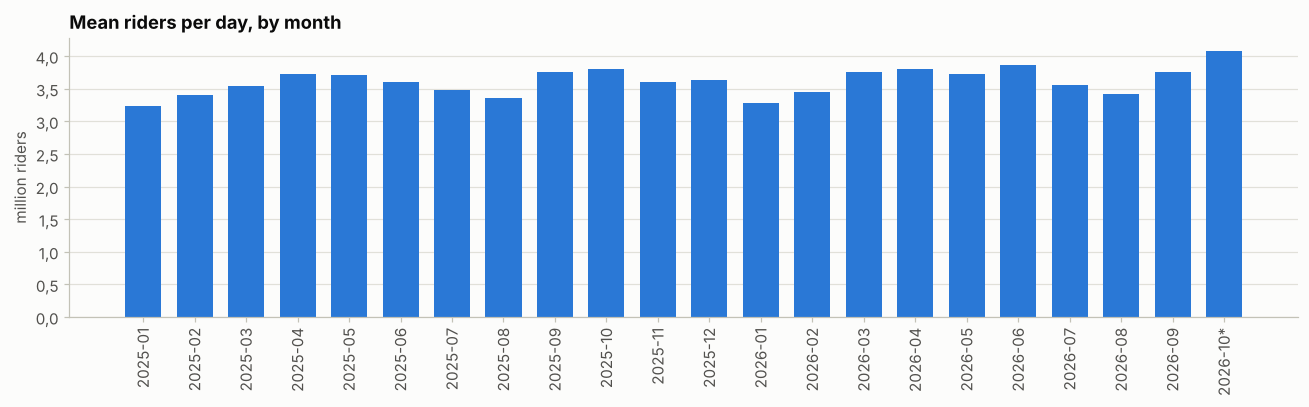

In [12]:
monthly = daily.assign(month=daily["day"].dt.to_period("M")).groupby("month").agg(days=("day", "count"), mean_daily=("riders", "mean")).reset_index()
monthly["label"] = monthly["month"].astype(str) + np.where(monthly["days"] < monthly["month"].dt.days_in_month, "*", "")

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(monthly["label"], monthly["mean_daily"], color=BLUE, width=0.7)
ax.set(title="Mean riders per day, by month", ylabel="million riders")
ax.yaxis.set_major_formatter(MILLIONS)
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

Perbandingan bulan yang sama pada 2025 dan 2026 (Januari sampai September, bulan yang lengkap pada kedua tahun):

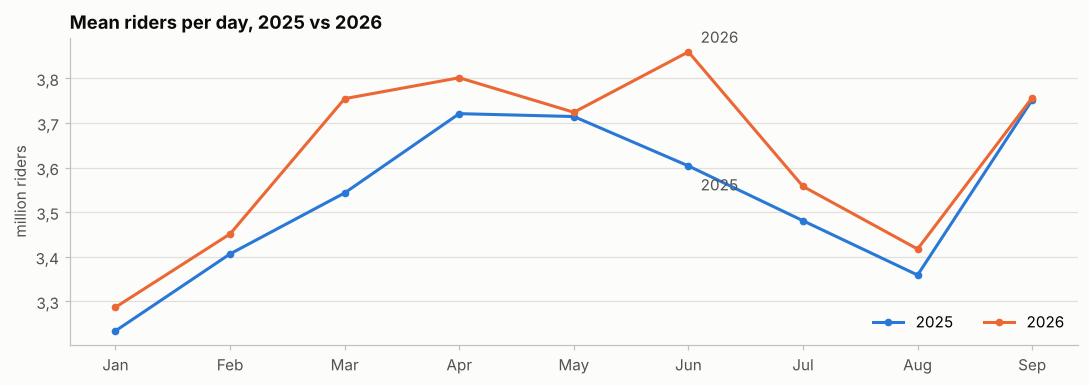

month,mean_daily_2025,mean_daily_2026,change_pct
1,3.234.003,3.287.018,"1,6"
2,3.406.544,3.451.361,"1,3"
3,3.543.279,3.754.661,"6,0"
4,3.721.042,3.801.507,"2,2"
5,3.714.575,3.724.153,"0,3"
6,3.603.823,3.859.547,"7,1"
7,3.480.915,3.557.918,"2,2"
8,3.359.175,3.417.502,"1,7"
9,3.751.687,3.756.679,"0,1"


In [13]:
yoy = monthly.assign(year=monthly["month"].dt.year, mon=monthly["month"].dt.month).pivot(index="mon", columns="year", values="mean_daily").loc[1:9]
yoy["change_pct"] = 100 * (yoy[2026] / yoy[2025] - 1)

fig, ax = plt.subplots(figsize=(10, 3.6))
for year, color in [(2025, BLUE), (2026, ORANGE)]:
    ax.plot(yoy.index, yoy[year], color=color, marker="o", markersize=4, label=str(year))
    ax.annotate(str(year), (6, yoy.loc[6, year]), xytext=(8, 6 if year == 2026 else -16), textcoords="offset points", color=INK_2)
ax.set(title="Mean riders per day, 2025 vs 2026", ylabel="million riders", xticks=range(1, 10),
       xticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep"])
ax.yaxis.set_major_formatter(MILLIONS)
ax.legend(loc="lower right", ncols=2)
plt.tight_layout()
plt.show()

show_table(yoy.round({2025: 0, 2026: 0}).reset_index().astype({2025: "int64", 2026: "int64"}).rename(columns={"mon": "month", 2025: "mean_daily_2025", 2026: "mean_daily_2026"}), 1)

**Temuan:**

- Pola musiman berulang pada kedua tahun: rata-rata harian terendah pada Januari (3,23-3,29 juta) dan Agustus (3,36-3,42 juta), dan tertinggi pada musim semi serta September-Oktober.
- Setiap bulan Januari sampai September 2026 lebih ramai daripada bulan yang sama pada 2025, dengan kenaikan antara 0,1% (September) dan 7,1% (Juni).
- Oktober 2026 baru berisi 8 hari, 6 di antaranya hari kerja, sehingga rata-ratanya (4,08 juta) lebih tinggi daripada bulan lain dan belum sebanding.
- Implikasi: tren tahunan yang naik dan pola musiman perlu masuk ke model, mis. lewat fitur bulan atau perbandingan dengan periode yang sama tahun sebelumnya.

#### 5. Metode Pembayaran: OMNY dan MetroCard

Porsi penumpang yang membayar dengan OMNY setiap bulan:

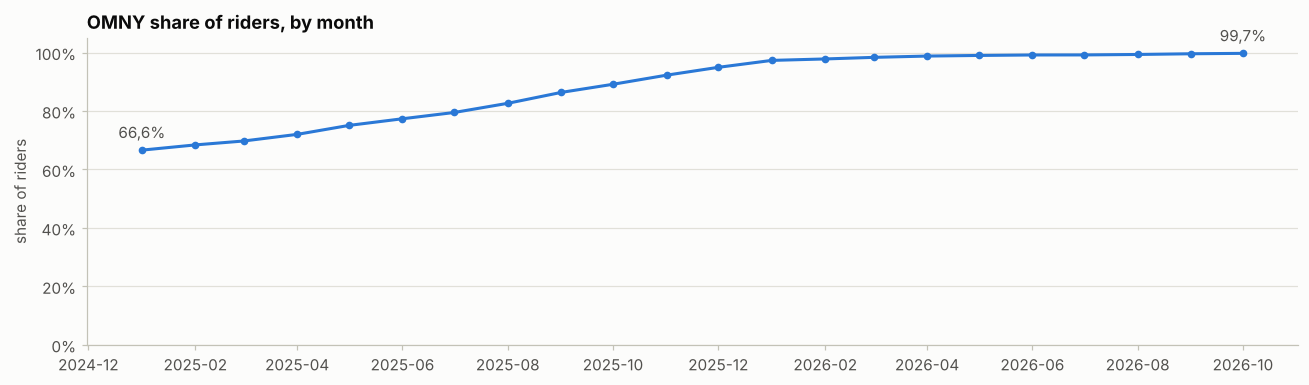

In [14]:
payment = con.sql("""
    SELECT date_trunc('month', transit_timestamp) AS month,
           100.0 * sum(ridership) FILTER (WHERE payment_method = 'omny') / sum(ridership) AS omny_pct
    FROM mta GROUP BY 1 ORDER BY 1""").df()

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(payment["month"], payment["omny_pct"], color=BLUE, marker="o", markersize=4)
for i in (0, len(payment) - 1):
    ax.annotate(f"{fmt(payment['omny_pct'].iloc[i], 1)}%", (payment["month"].iloc[i], payment["omny_pct"].iloc[i]),
                xytext=(0, 8), textcoords="offset points", ha="center", color=INK_2)
ax.set(title="OMNY share of riders, by month", ylabel="share of riders", ylim=(0, 105))
ax.yaxis.set_major_formatter(PERCENT)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout()
plt.show()

Penumpang per kelas tarif, dipisah per tahun untuk melihat pergeseran antarkelas:

In [15]:
fares = con.sql("""
    SELECT fare_class_category, year(transit_timestamp) AS year, sum(ridership) AS riders
    FROM mta GROUP BY 1, 2""").df().pivot(index="fare_class_category", columns="year", values="riders").fillna(0).astype("int64")
for year in fares.columns:
    fares[f"share_{year}_pct"] = 100 * fares[year] / fares[year].sum()
show_table(fares.sort_values(2025, ascending=False).reset_index().rename(columns={2025: "riders_2025", 2026: "riders_2026"}), 2)

fare_class_category,riders_2025,riders_2026,share_2025_pct,share_2026_pct
OMNY - Full Fare,878.860.900,827.223.695,"67,42","80,96"
OMNY - Students,81.038.456,59.261.123,"6,22","5,80"
Metrocard - Full Fare,72.734.594,649.234,"5,58","0,06"
Metrocard - Unlimited 30-Day,60.621.895,1.559.412,"4,65","0,15"
Metrocard - Unlimited 7-Day,55.551.758,489.587,"4,26","0,05"
OMNY - Seniors & Disability,47.917.673,57.347.750,"3,68","5,61"
Metrocard - Other,36.917.451,9.459.536,"2,83","0,93"
OMNY - Fair Fare,23.482.665,41.333.017,"1,80","4,05"
Metrocard - Fair Fare,23.059.119,3.436,"1,77","0,00"
Metrocard - Seniors & Disability,14.884.482,264.835,"1,14","0,03"


**Temuan:**

- Porsi OMNY naik dari 66,6% (Januari 2025) menjadi 99,7% (Oktober 2026). Porsinya melewati 90% pada November 2025 (92,3%), 95% pada Januari 2026 (97,3%), dan 99% pada Mei 2026 (99,0%).
- Peralihan terlihat di semua kelas tarif. Penumpang MetroCard tarif penuh turun dari 72,7 juta pada 2025 menjadi 0,65 juta pada 2026, dan kartu langganan MetroCard 7 hari dan 30 hari hampir hilang. Sebaliknya, porsi OMNY tarif penuh naik dari 67,4% menjadi 81,0%, dan kelas *Fair Fare* serta lansia dan disabilitas pindah ke OMNY.
- Implikasi: transisi ke OMNY praktis sudah selesai pada awal 2026. Analisis adopsi OMNY paling relevan pada rentang 2025, sedangkan untuk model 2026 `payment_method` hampir tidak lagi membedakan apa pun.

#### 6. Stasiun dan *Borough*

Sebaran penumpang dan stasiun per *borough*:

In [16]:
boroughs = stations.groupby("borough").agg(stations=("station_complex_id", "count"), riders=("riders", "sum")).sort_values("riders", ascending=False)
boroughs["share_pct"] = 100 * boroughs["riders"] / boroughs["riders"].sum()
boroughs["avg_daily_per_station"] = (boroughs["riders"] / boroughs["stations"] / N_DAYS).round().astype("int64")
show_table(boroughs.reset_index(), 1)

borough,stations,riders,share_pct,avg_daily_per_station
Manhattan,123,1.300.691.376,"55,9",16.370
Brooklyn,156,518.971.144,"22,3",5.150
Queens,79,342.619.993,"14,7",6.714
Bronx,68,159.205.335,"6,8",3.624
Staten Island,2,3.899.184,"0,2",3.018


Sepuluh kompleks stasiun dengan rata-rata penumpang harian tertinggi:

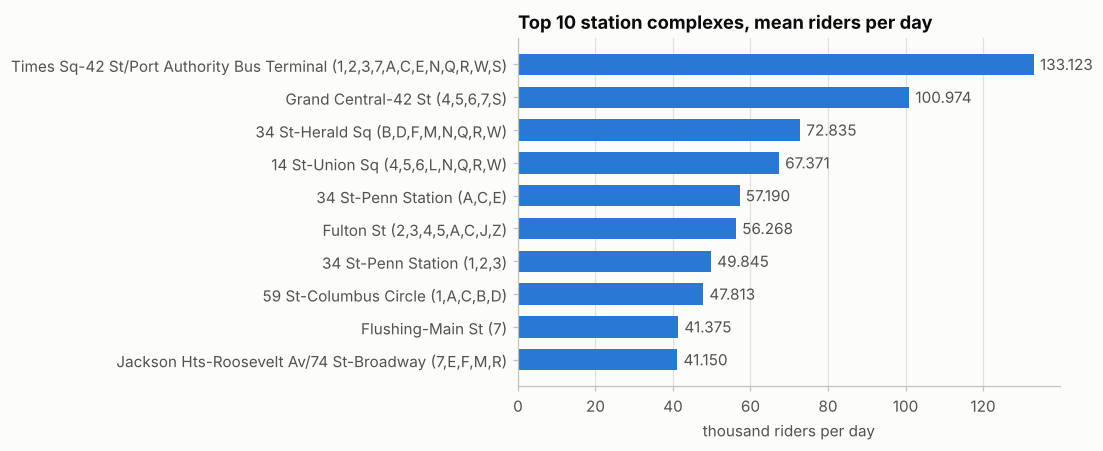

Top 10 complexes carry 18,6% of all riders; top 50 carry 45,3%.


In [17]:
top = stations.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(top["station_complex"], top["avg_daily"], color=BLUE, height=0.65)
for y, value in enumerate(top["avg_daily"]):
    ax.annotate(fmt(value), (value, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK_2)
ax.set(title="Top 10 station complexes, mean riders per day", xlabel="riders per day")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel("thousand riders per day")
plt.tight_layout()
plt.show()

print(f"Top 10 complexes carry {fmt(100 * stations['riders'].head(10).sum() / riders, 1)}% of all riders; "
      f"top 50 carry {fmt(100 * stations['riders'].head(50).sum() / riders, 1)}%.")

Lokasi setiap kompleks stasiun; luas lingkaran sebanding dengan rata-rata penumpang harian. Lingkaran terbesar di Midtown Manhattan adalah stasiun-stasiun teratas pada grafik sebelumnya.

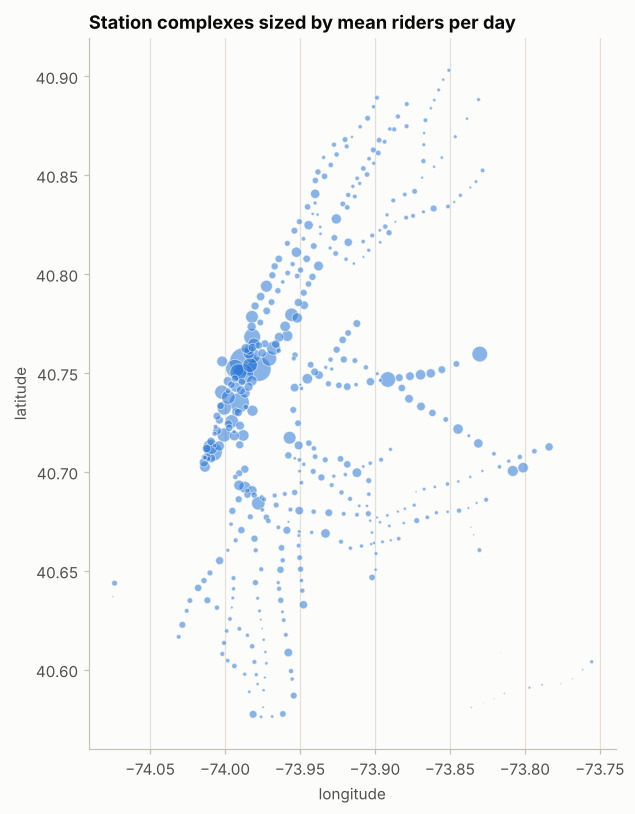

In [18]:
fig, ax = plt.subplots(figsize=(7, 7.5))
ax.scatter(stations["longitude"], stations["latitude"], s=stations["avg_daily"] / 400, color=BLUE, alpha=0.55, edgecolors=SURFACE, linewidths=0.6)
ax.set(title="Station complexes sized by mean riders per day", xlabel="longitude", ylabel="latitude")
ax.set_aspect(1 / np.cos(np.radians(40.7)))
ax.grid(axis="both")
plt.tight_layout()
plt.show()

**Temuan:**

- Manhattan memiliki 123 dari 428 kompleks stasiun (29%) tetapi menampung 55,9% penumpang. Rata-rata satu stasiun Manhattan melayani 16.370 penumpang per hari, sekitar 4,5 kali stasiun Bronx (3.624).
- Times Sq-42 St (133.123 penumpang per hari) dan Grand Central-42 St (100.974) jauh di atas stasiun lain. Sepuluh kompleks teratas menampung 18,6% penumpang dan 50 kompleks teratas 45,3%.
- Di luar Manhattan, stasiun besar adalah simpul transportasi seperti Flushing-Main St dan Jackson Hts-Roosevelt Av/74 St-Broadway.
- 34 St-Penn Station tercatat sebagai dua kompleks terpisah (jalur A,C,E dan jalur 1,2,3); hal ini perlu diingat saat memetakan stasiun ke `stop_id` GTFS pada tahap *streaming*.
- Implikasi: skala penumpang antarstasiun sangat timpang, sehingga model regresi perlu target yang ditransformasi atau fitur identitas stasiun.

#### 7. Profil Jam per Stasiun

Penumpang dalam data ini adalah orang yang **masuk** ke stasiun. Stasiun di kawasan permukiman ramai pada pagi hari (warga berangkat), sedangkan stasiun di kawasan perkantoran ramai pada sore hari (pekerja pulang). Profil setiap stasiun dihitung dari hari kerja sebagai porsi penumpang per jam terhadap total hariannya, lalu diringkas menjadi porsi pagi (06:00-09:59) dan porsi sore (16:00-19:59).

In [19]:
station_hour = con.sql("""
    SELECT station_complex_id, hour(transit_timestamp) AS hour, sum(ridership) AS riders
    FROM mta WHERE NOT is_dst_transition AND isodow(transit_timestamp) <= 5
    GROUP BY 1, 2""").df().pivot(index="station_complex_id", columns="hour", values="riders").fillna(0)
shape = station_hour.div(station_hour.sum(axis=1), axis=0)

stations = stations.set_index("station_complex_id")
stations["am_share"] = 100 * shape[list(AM_HOURS)].sum(axis=1)
stations["pm_share"] = 100 * shape[list(PM_HOURS)].sum(axis=1)
stations = stations.reset_index()

busy = stations.head(50)
examples = {
    "Morning-heavy (residential)": busy.loc[(busy["am_share"] - busy["pm_share"]).idxmax()],
    "Evening-heavy (office)": busy.loc[(busy["pm_share"] - busy["am_share"]).idxmax()],
    "Balanced": busy.loc[(busy["am_share"] - busy["pm_share"]).abs().idxmin()],
}
show_table(pd.DataFrame([(k, v["station_complex"], v["borough"], round(v["avg_daily"]), v["am_share"], v["pm_share"]) for k, v in examples.items()],
                        columns=["profile", "station_complex", "borough", "avg_daily", "am_share_pct", "pm_share_pct"]), 1)

profile,station_complex,borough,avg_daily,am_share_pct,pm_share_pct
Morning-heavy (residential),Junction Blvd (7),Queens,18.146,"44,6","14,6"
Evening-heavy (office),"47-50 Sts-Rockefeller Ctr (B,D,F,M)",Manhattan,37.486,"3,3","56,2"
Balanced,Bedford Av (L),Brooklyn,27.418,"27,7","27,8"


Profil jam hari kerja tiga stasiun contoh di atas (dipilih dari 50 stasiun tersibuk):

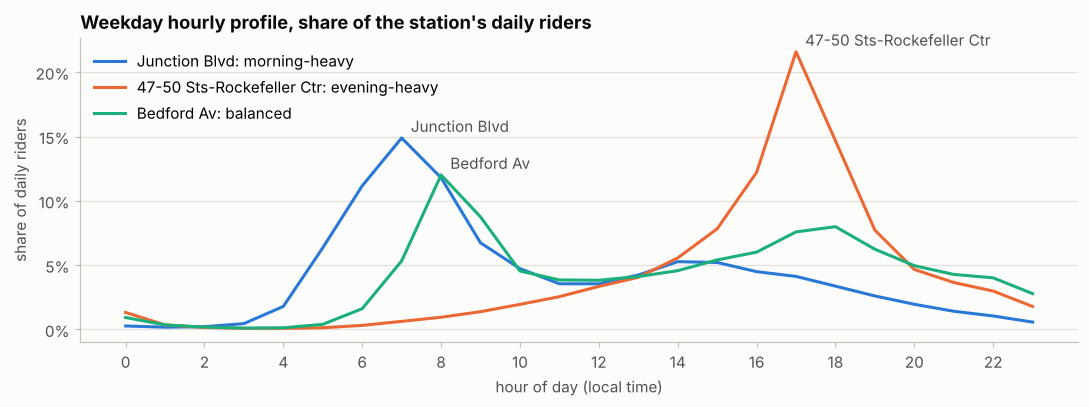

In [20]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for (label, row), color in zip(examples.items(), [BLUE, ORANGE, AQUA]):
    values = 100 * shape.loc[row["station_complex_id"]]
    name = row["station_complex"].split(" (")[0]
    ax.plot(values.index, values.values, color=color, label=f"{name}: {label.split(' (')[0].lower()}")
    peak = values.idxmax()
    ax.annotate(name, (peak, values[peak]), xytext=(6, 4), textcoords="offset points", color=INK_2)
ax.set(title="Weekday hourly profile, share of the station's daily riders", xlabel="hour of day (local time)", ylabel="share of daily riders", xticks=range(0, 24, 2))
ax.yaxis.set_major_formatter(PERCENT)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Porsi pagi dan sore untuk seluruh 428 kompleks stasiun. Stasiun di atas garis diagonal lebih ramai pada sore hari; luas lingkaran sebanding dengan rata-rata penumpang harian.

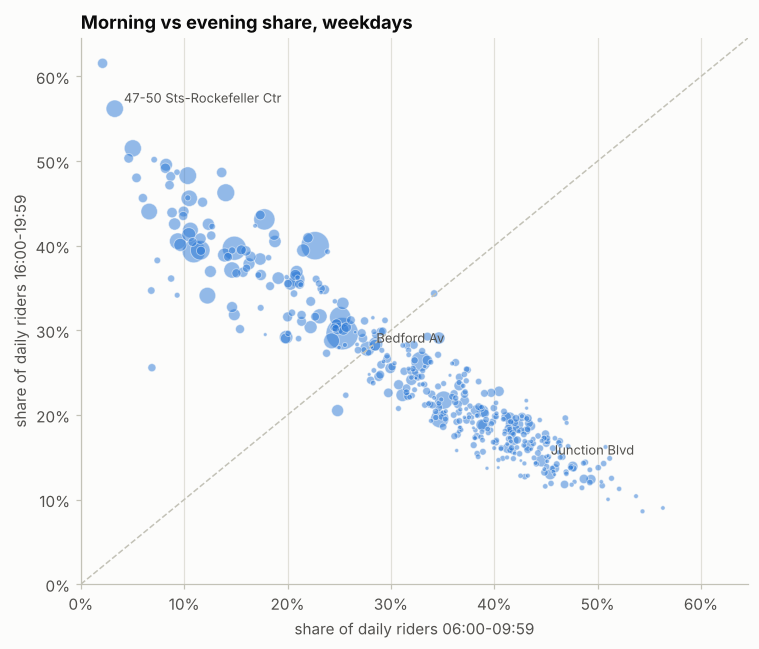

Morning-heavy complexes: 297 | evening-heavy: 131


In [21]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(stations["am_share"], stations["pm_share"], s=stations["avg_daily"] / 300 + 4, color=BLUE, alpha=0.5, edgecolors=SURFACE, linewidths=0.6)
limit = max(stations["am_share"].max(), stations["pm_share"].max()) + 3
ax.plot([0, limit], [0, limit], color=AXIS, linewidth=1, linestyle="--")
for row in examples.values():
    ax.annotate(row["station_complex"].split(" (")[0], (row["am_share"], row["pm_share"]), xytext=(6, 4), textcoords="offset points", color=INK_2, fontsize=8.5)
ax.set(title="Morning vs evening share, weekdays", xlabel="share of daily riders 06:00-09:59", ylabel="share of daily riders 16:00-19:59", xlim=(0, limit), ylim=(0, limit))
ax.xaxis.set_major_formatter(PERCENT)
ax.yaxis.set_major_formatter(PERCENT)
ax.grid(axis="both")
plt.tight_layout()
plt.show()

morning = (stations["am_share"] > stations["pm_share"]).sum()
print(f"Morning-heavy complexes: {morning} | evening-heavy: {len(stations) - morning}")

**Temuan:**

- 297 kompleks lebih ramai pada pagi hari (pola permukiman) dan 131 lebih ramai pada sore hari (pola perkantoran). Stasiun pola sore lebih sedikit tetapi umumnya besar (rata-rata 15.753 penumpang per hari, dibanding 5.172 untuk stasiun pola pagi), sesuai konsentrasi perkantoran di Manhattan.
- Contoh ekstrem dari 50 stasiun tersibuk: Junction Blvd di Queens menerima 44,6% penumpang hariannya pada 06.00-09.59 dan hanya 14,6% pada 16.00-19.59, sedangkan 47-50 Sts-Rockefeller Ctr di Manhattan menerima 3,3% pada pagi hari dan 56,2% pada sore hari. Bedford Av di Brooklyn seimbang (27,7% dan 27,8%).
- Titik-titik pada grafik pagi-sore membentuk satu pita yang menurun, bukan kelompok yang terpisah jelas.
- Implikasi untuk K-Means: profil 24 jam dalam bentuk porsi (bukan jumlah penumpang) adalah fitur yang tepat, karena tidak dipengaruhi ukuran stasiun. Karena polanya berupa kontinum, jumlah *cluster* perlu dipilih dengan metrik seperti *elbow* atau *silhouette*.

#### 8. Distribusi Target Regresi

Target regresi pada rencana proyek adalah penumpang per stasiun per jam. Satu baris dataset masih dipecah menurut metode pembayaran dan kelas tarif, sehingga baris dijumlahkan dulu menjadi satu nilai per kompleks stasiun per jam. Kombinasi jam dan stasiun yang tidak punya penumpang tidak tercatat sama sekali di dataset, sehingga kepadatannya perlu diukur.

In [22]:
con.execute("""
    CREATE OR REPLACE TABLE station_hours AS
    SELECT transit_timestamp, station_complex_id, sum(ridership) AS riders
    FROM mta WHERE NOT is_dst_transition GROUP BY 1, 2""")
present, n_hours = con.sql("SELECT count(*), count(DISTINCT transit_timestamp) FROM station_hours").fetchone()
stats = con.sql("""
    SELECT min(riders), quantile_cont(riders, 0.5), avg(riders), quantile_cont(riders, 0.95), quantile_cont(riders, 0.99), max(riders),
           skewness(riders), skewness(ln(1 + riders))
    FROM station_hours""").fetchone()

show_table(pd.DataFrame([
    ("Station-hours present", fmt(present)),
    ("Possible station-hours (complexes x hours)", fmt(len(stations) * n_hours)),
    ("Present share", f"{fmt(100 * present / (len(stations) * n_hours), 2)}%"),
    ("Riders per station-hour: min / median / mean", f"{fmt(stats[0])} / {fmt(stats[1])} / {fmt(stats[2], 1)}"),
    ("Riders per station-hour: p95 / p99 / max", f"{fmt(stats[3])} / {fmt(stats[4])} / {fmt(stats[5])}"),
    ("Skewness: riders / log(1 + riders)", f"{fmt(stats[6], 2)} / {fmt(stats[7], 2)}"),
], columns=["Metric", "Value"]))

Metric,Value
Station-hours present,6.502.775
Possible station-hours (complexes x hours),6.634.428
Present share,"98,02%"
Riders per station-hour: min / median / mean,"1 / 139 / 357,6"
Riders per station-hour: p95 / p99 / max,1.371 / 3.395 / 25.147
Skewness: riders / log(1 + riders),"7,66 / -0,27"


Histogram penumpang per stasiun per jam, dalam skala asli (dipotong pada persentil ke-99 agar terbaca) dan setelah transformasi $\log(1 + \text{ridership})$. Karena `ridership` selalu bilangan bulat, batas kelas histogram kanan disejajarkan dengan bilangan bulat dan sumbu tegaknya memakai kepadatan (*density*).

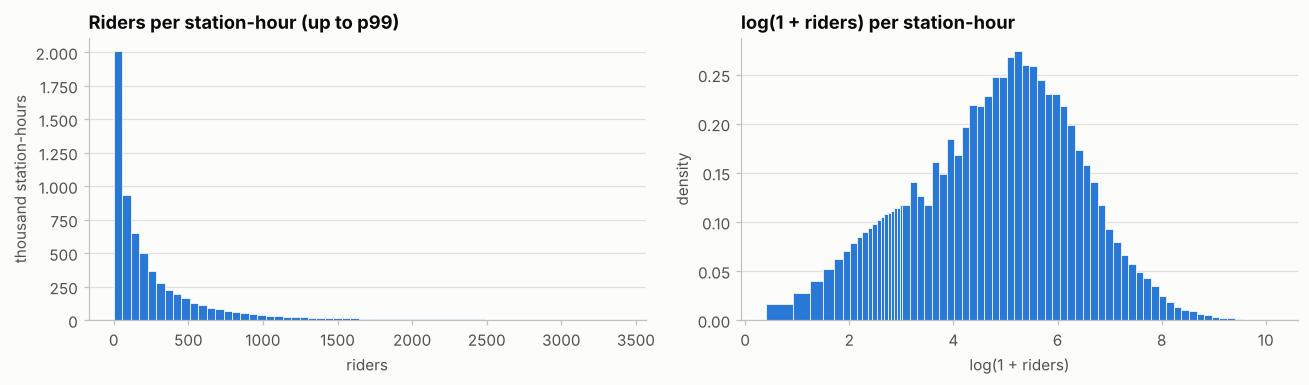

In [23]:
values = con.sql("SELECT riders FROM station_hours").fetchnumpy()["riders"]

fig, (ax_raw, ax_log) = plt.subplots(1, 2, figsize=(12, 3.6))
ax_raw.hist(values[values <= stats[4]], bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax_raw.set(title="Riders per station-hour (up to p99)", xlabel="riders", ylabel="thousand station-hours")
edges = np.log1p(np.unique(np.concatenate([np.arange(0.5, 20, 1), np.geomspace(19.5, values.max() + 0.5, 50)])))  # riders are whole numbers
ax_log.hist(np.log1p(values), bins=edges, density=True, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax_log.set(title="log(1 + riders) per station-hour", xlabel="log(1 + riders)", ylabel="density")
ax_raw.yaxis.set_major_formatter(THOUSANDS)
plt.tight_layout()
plt.show()
del values

**Temuan:**

- 98,02% kombinasi stasiun dan jam tercatat. Sebanyak 131.653 kombinasi tidak muncul sama sekali, 46,3% di antaranya pada pukul 00.00-05.59. Bagi model, kombinasi ini berarti nol penumpang atau stasiun tutup, sehingga perlu diisi secara eksplisit sebelum membuat fitur jeda waktu (*lag*).
- Penumpang per stasiun per jam sangat condong ke kanan: median 139, rata-rata 357,6, persentil ke-99 3.395, maksimum 25.147, dengan *skewness* 7,66.
- Setelah transformasi $\log(1 + \text{ridership})$, *skewness* turun menjadi -0,27 dan bentuknya mendekati simetris. Ini mendukung pilihan target regresi pada rencana proyek.

#### 9. Ringkasan Temuan

- **Volume:** rata-rata 3,60 juta penumpang per hari (hari kerja 4,05 juta, akhir pekan 2,46 juta), dan setiap bulan pada 2026 lebih ramai daripada bulan yang sama pada 2025.
- **Pola waktu:** hari kerja memiliki puncak pukul 08.00 dan 17.00, sedangkan akhir pekan hanya memiliki satu puncak landai sekitar pukul 16.00. Hari libur dan dua kejadian pada Januari dan Februari 2026 menurunkan penumpang secara tajam.
- **Pembayaran:** OMNY naik dari 66,6% menjadi 99,7% porsi penumpang; transisi praktis selesai pada awal 2026.
- **Stasiun:** penumpang terkonsentrasi di Manhattan (55,9%) dan di sedikit stasiun besar (50 kompleks menampung 45,3%).
- **Profil stasiun:** 297 kompleks berpola pagi (permukiman) dan 131 berpola sore (perkantoran), membentuk kontinum.
- **Target regresi:** sangat condong ke kanan, tetapi mendekati simetris setelah $\log(1 + \text{ridership})$; 1,98% kombinasi stasiun-jam yang tidak tercatat perlu diisi nol.

Untuk tahap pemodelan, fitur yang terlihat penting adalah jam, hari dalam pekan, tipe hari (kerja atau akhir pekan), hari libur, bulan, identitas atau profil stasiun, dan penanda hari anomali.